Loaded Well-A_processed.csv with 3805 samples.
Loaded Well-C_processed.csv with 4134 samples.


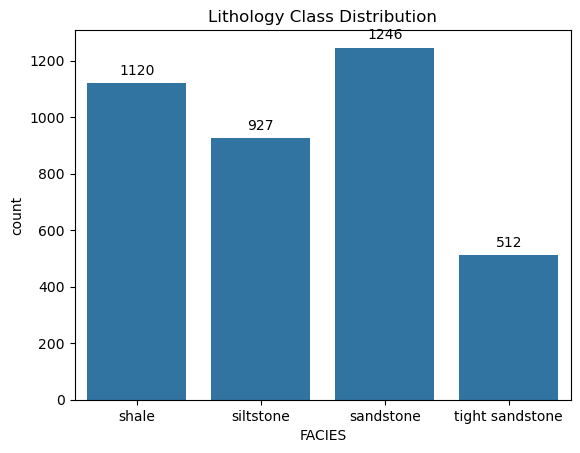

Facies classes: ['sandstone' 'shale' 'siltstone' 'tight sandstone']


BASE MODEL PERFORMANCE
RandomForest    | ACC=0.9099 | F1=0.9088 | PREC=0.9098 | TIME=38.9s
ExtraTrees      | ACC=0.9062 | F1=0.9051 | PREC=0.9063 | TIME=4.9s
AdaBoost        | ACC=0.7611 | F1=0.7578 | PREC=0.7623 | TIME=7.1s
GradientBoosting | ACC=0.9093 | F1=0.9085 | PREC=0.9090 | TIME=108.7s
SVM             | ACC=0.8633 | F1=0.8626 | PREC=0.8646 | TIME=15.5s
KNN             | ACC=0.8447 | F1=0.8424 | PREC=0.8442 | TIME=2.4s
MLP             | ACC=0.8665 | F1=0.8648 | PREC=0.8655 | TIME=16.3s
LogReg          | ACC=0.8512 | F1=0.8508 | PREC=0.8539 | TIME=1.2s
GNB             | ACC=0.7963 | F1=0.7886 | PREC=0.7991 | TIME=0.4s
LGBM            | ACC=0.9325 | F1=0.9324 | PREC=0.9326 | TIME=143.1s
CatBoost        | ACC=0.9338 | F1=0.9334 | PREC=0.9336 | TIME=717.2s
XGBoost         | ACC=0.9311 | F1=0.9309 | PREC=0.9311 | TIME=11.6s


MODEL ANALYTICS
                  accuracy  precision    recall        f1    time_sec
CatB

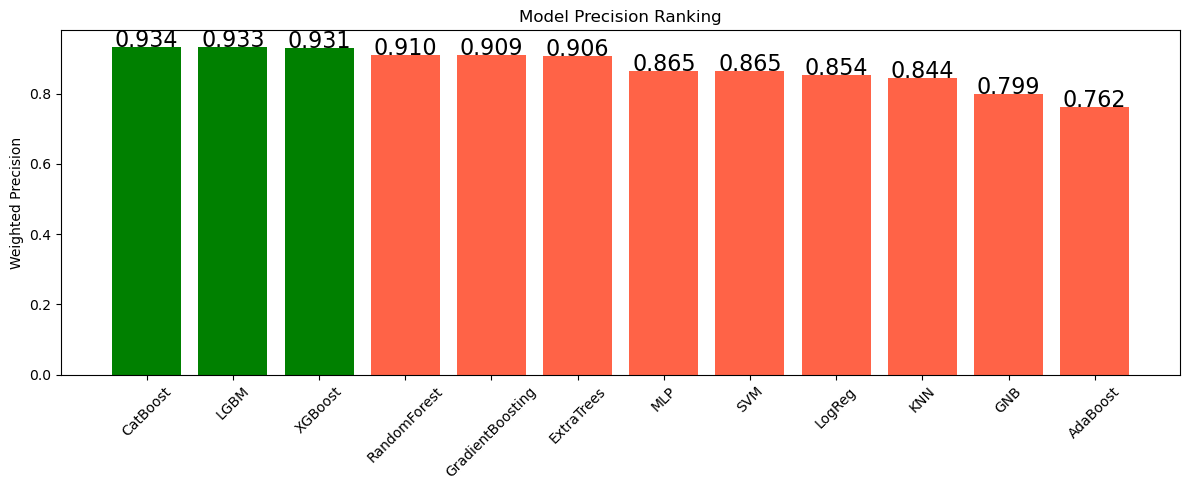



HYPERPARAMETER TUNING

Tuning CatBoost
0:	learn: 1.3039304	total: 146ms	remaining: 43.8s
1:	learn: 1.2339634	total: 183ms	remaining: 27.2s
2:	learn: 1.1680506	total: 208ms	remaining: 20.6s
3:	learn: 1.1103471	total: 240ms	remaining: 17.8s
4:	learn: 1.0602498	total: 270ms	remaining: 15.9s
5:	learn: 1.0134339	total: 299ms	remaining: 14.7s
6:	learn: 0.9691440	total: 320ms	remaining: 13.4s
7:	learn: 0.9294740	total: 346ms	remaining: 12.6s
8:	learn: 0.8940278	total: 380ms	remaining: 12.3s
9:	learn: 0.8613572	total: 413ms	remaining: 12s
10:	learn: 0.8335534	total: 444ms	remaining: 11.7s
11:	learn: 0.8067832	total: 469ms	remaining: 11.3s
12:	learn: 0.7802037	total: 497ms	remaining: 11s
13:	learn: 0.7554807	total: 522ms	remaining: 10.7s
14:	learn: 0.7335788	total: 551ms	remaining: 10.5s
15:	learn: 0.7127572	total: 579ms	remaining: 10.3s
16:	learn: 0.6934709	total: 612ms	remaining: 10.2s
17:	learn: 0.6749371	total: 656ms	remaining: 10.3s
18:	learn: 0.6594372	total: 693ms	remaining: 10.3s
19:	

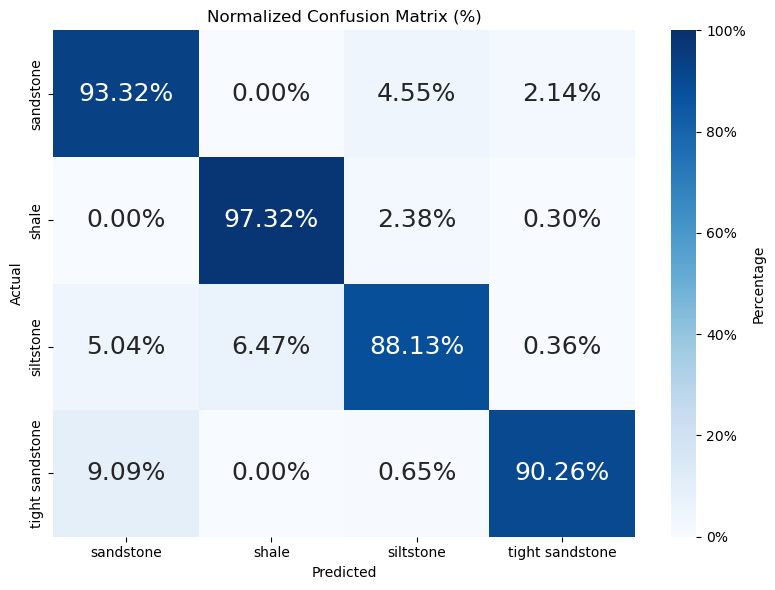

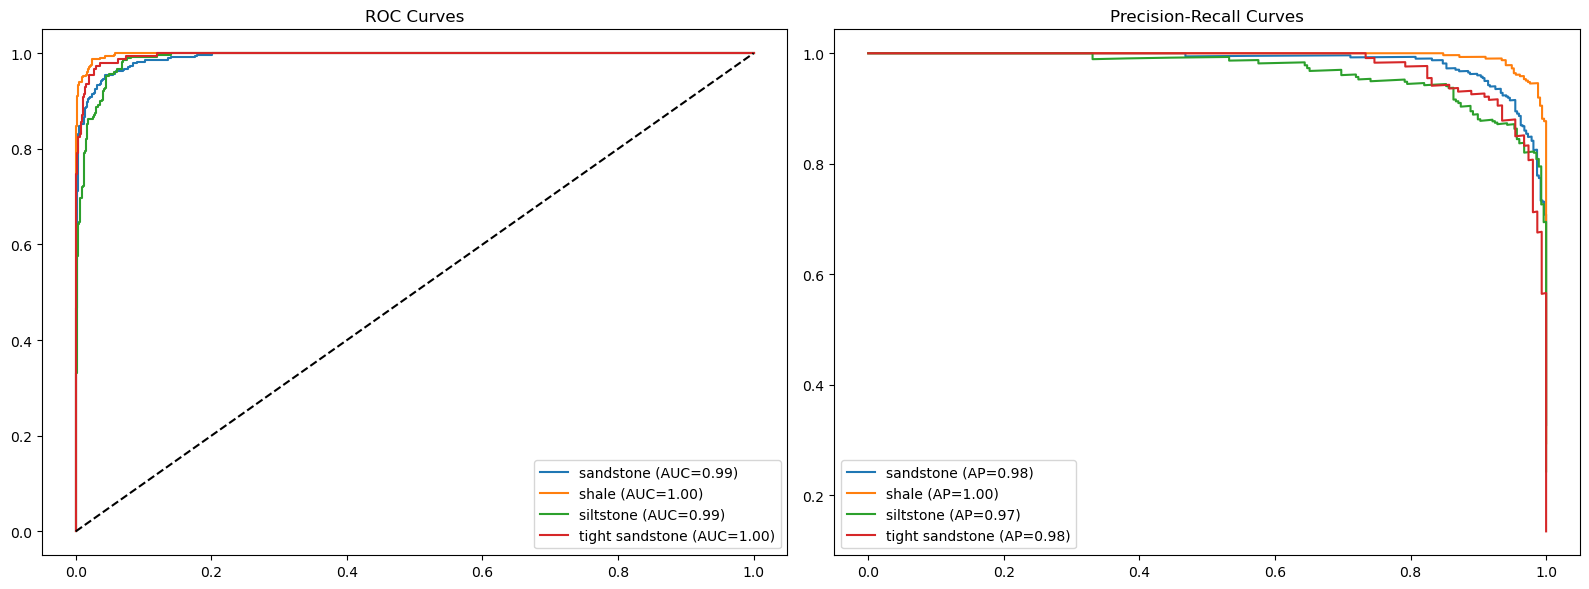



FEATURE IMPORTANCE

CatBoost Feature Importance
    Feature  Importance
1        RT   14.018492
19      SQI   11.785939
0        GR    9.161397
20   BI_PHI    8.345986
2      RHOB    6.504388
21  NET_RES    4.964592
9       YME    4.794128
11      BMK    4.434026
10       PR    4.104700
8      VpVs    4.057552


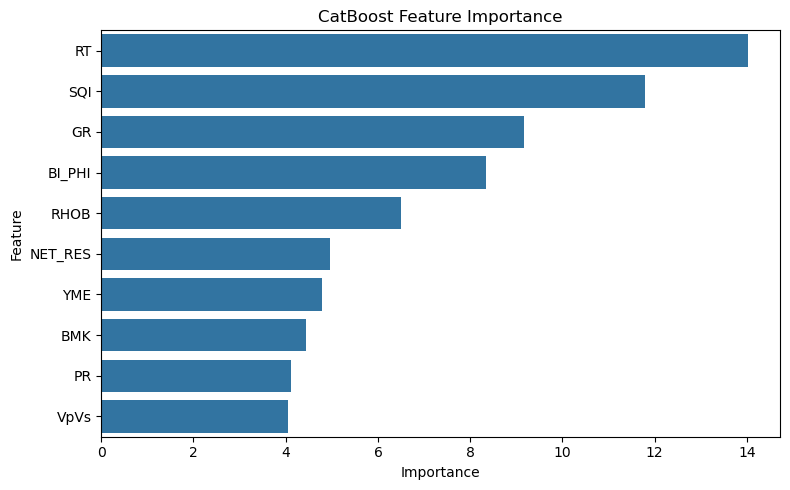


LGBM Feature Importance
        Feature  Importance
1            RT        6534
0            GR        6014
3          NPHI        5020
2          RHOB        4771
8          VpVs        3791
11          BMK        3371
9           YME        3368
19          SQI        3298
14  GR_RT_RATIO        2587
5          DTSM        2398


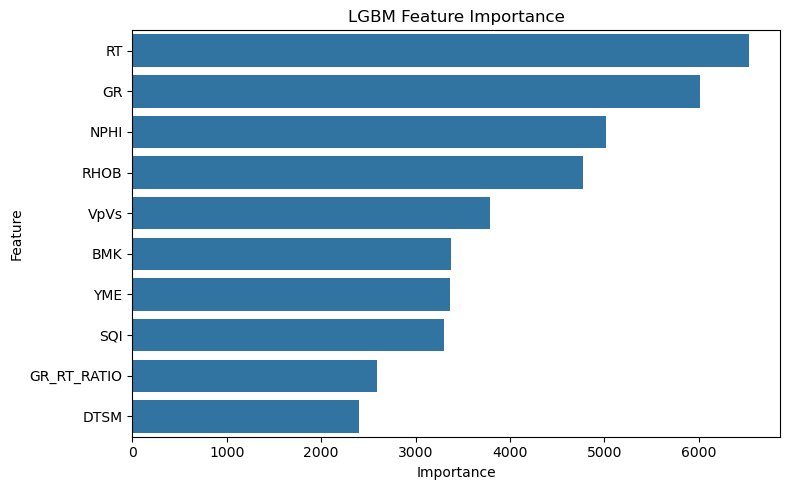


XGBoost Feature Importance
        Feature  Importance
21      NET_RES    0.446667
19          SQI    0.121106
20       BI_PHI    0.061174
9           YME    0.059703
1            RT    0.032622
12          SMG    0.031209
18  RQI_ELASTIC    0.026526
13           BI    0.025067
17           FI    0.020677
7            Vs    0.017482


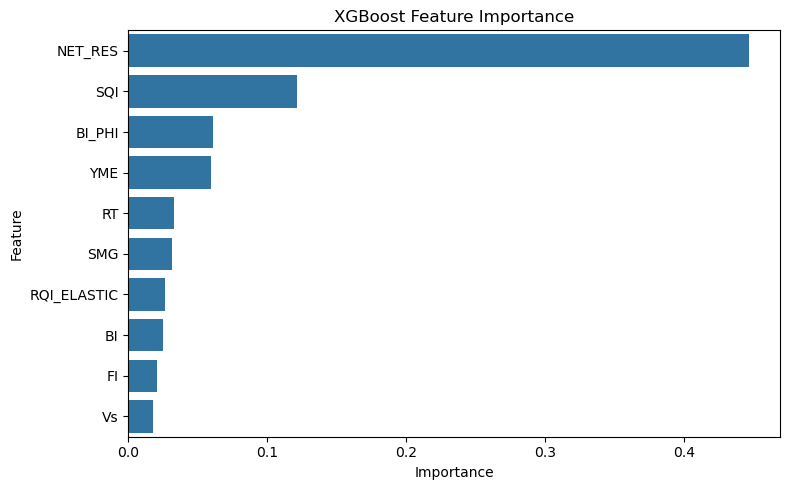



WELL-1 COMPLETE PREDICTION
Predictions for Well 1 saved to 'Final_Ensemble_Predictions_Well1.csv'

Classification Report for Full Well 1:
                 precision    recall  f1-score   support

      sandstone       0.98      0.98      0.98      1246
          shale       0.98      0.99      0.99      1120
      siltstone       0.97      0.96      0.97       927
tight sandstone       0.98      0.97      0.98       512

       accuracy                           0.98      3805
      macro avg       0.98      0.98      0.98      3805
   weighted avg       0.98      0.98      0.98      3805



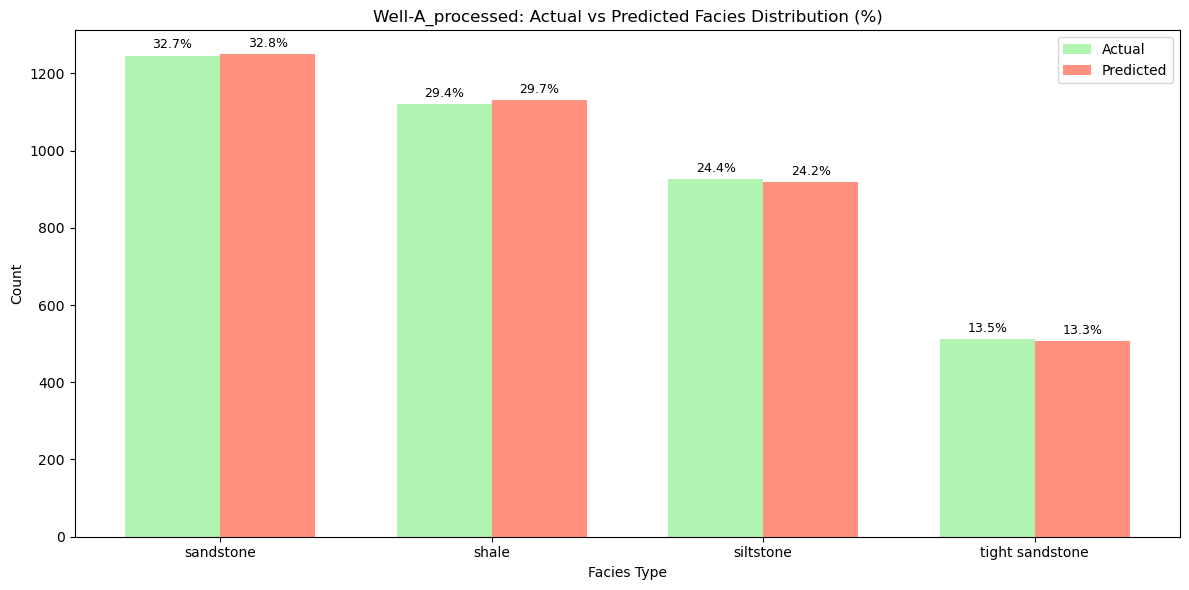



WELL-1 CONFUSION MATRIX


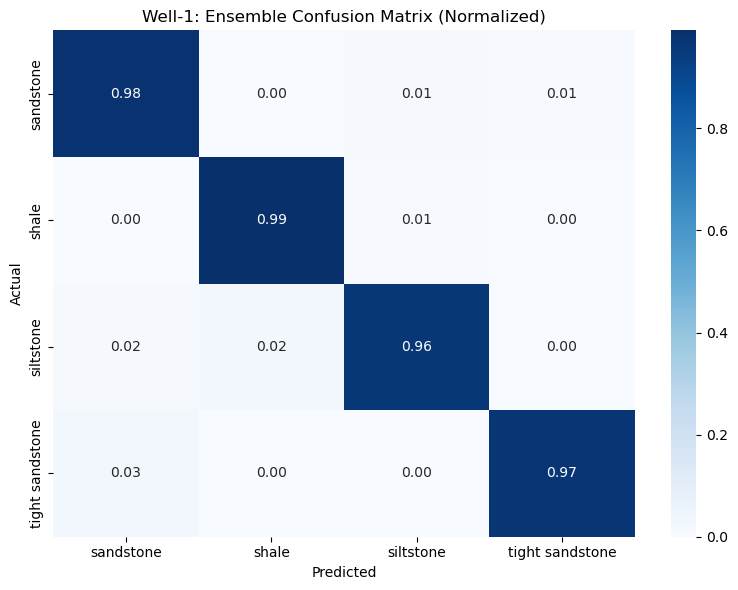


Generating ROC and PR Curves for Well-1...


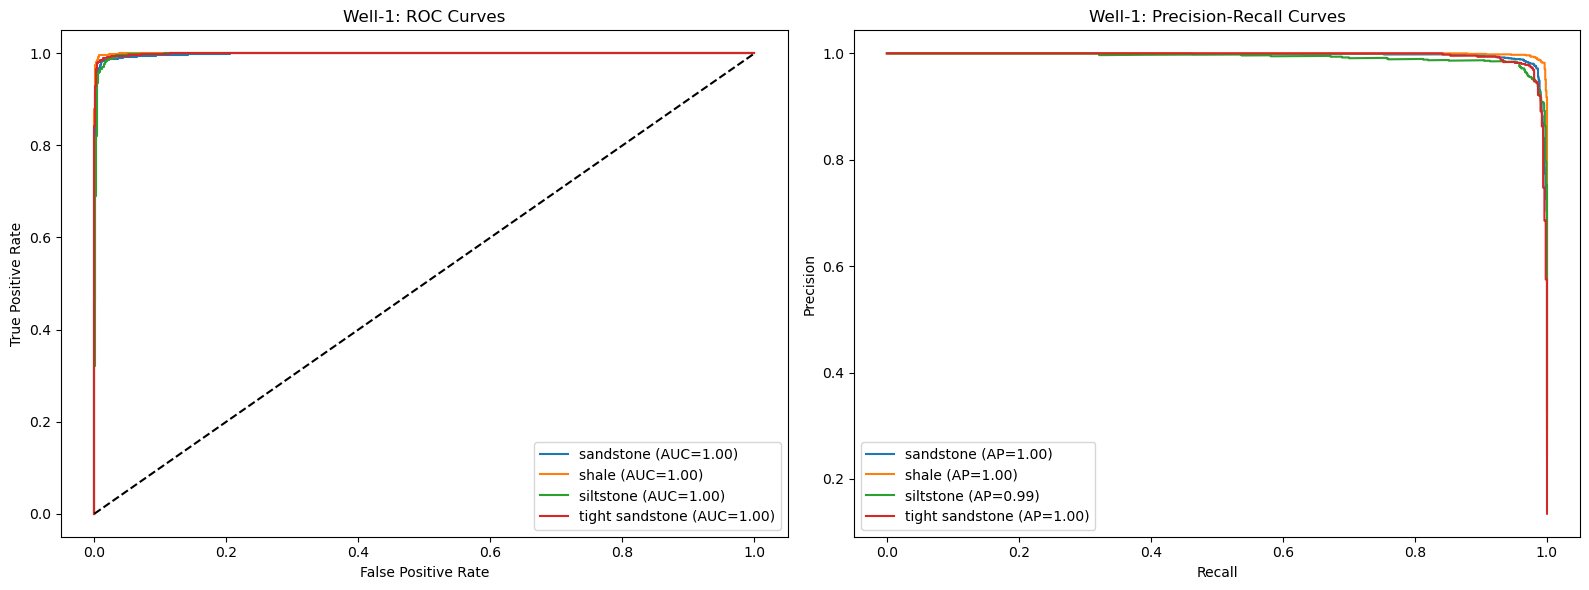



WELL-2 PREDICTION

WELL-2 CLASSIFICATION REPORT
                 precision    recall  f1-score   support

      sandstone       0.97      0.83      0.89      1719
          shale       0.96      0.88      0.92      1010
      siltstone       0.67      0.89      0.77       612
tight sandstone       0.80      0.94      0.86       793

       accuracy                           0.87      4134
      macro avg       0.85      0.88      0.86      4134
   weighted avg       0.89      0.87      0.88      4134



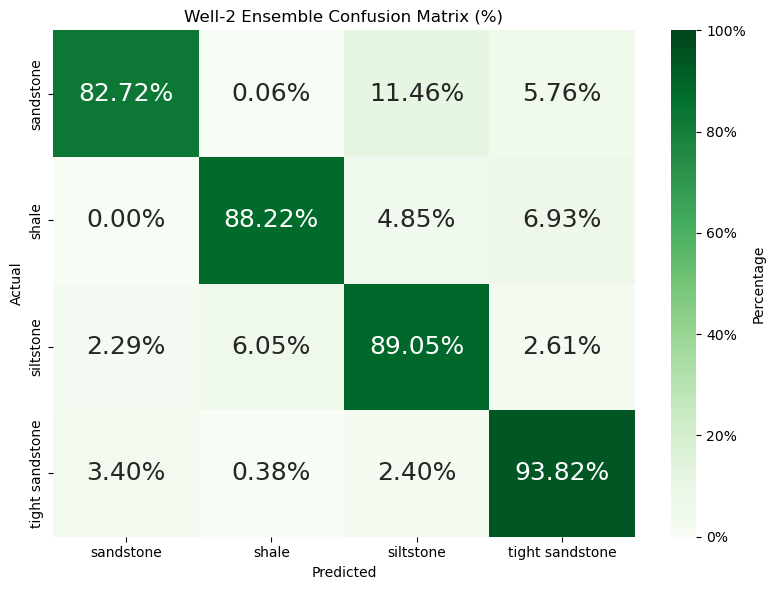

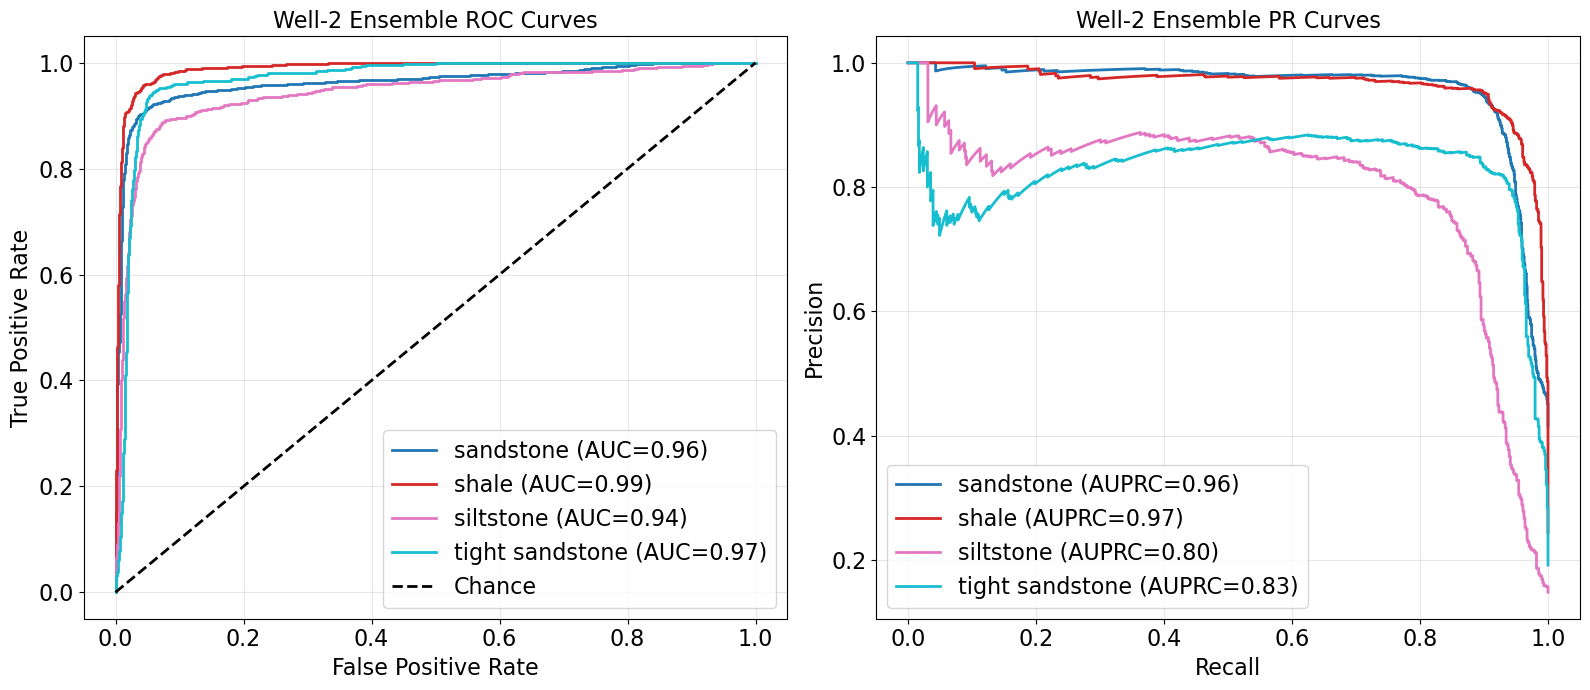



EXECUTION COMPLETED
Total Features : 22
Total Classes  : 4
Top Models     : ['CatBoost', 'LGBM', 'XGBoost']
Saved predictions to Well-C_processed_Ensemble_Predictions.csv


In [3]:
# ======================================================================
# Tight Sandstone Reservoir Facies Prediction
# ======================================================================

# ==========================================================
# 0. IMPORTS
# ==========================================================

import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

from sklearn import set_config
set_config(transform_output="pandas")

# ----------------------------------------------------------
# SKLEARN
# ----------------------------------------------------------

from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split,
    RandomizedSearchCV,
    cross_validate,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder,
    label_binarize
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    balanced_accuracy_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    log_loss
)

# ----------------------------------------------------------
# MODELS LIBRARIES
# ----------------------------------------------------------
# Machine Learning Classifiers

# Import for RandomForest
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.ensemble import VotingClassifier

# Import for XGBoost
from xgboost import XGBClassifier

# Import for SVM
from sklearn.svm import SVC

# Import for KNN
from sklearn.neighbors import KNeighborsClassifier

# Import for MLP
from sklearn.neural_network import MLPClassifier

# Import for LightGBM
from lightgbm import LGBMClassifier

# Import for Logistic Regression
from sklearn.linear_model import LogisticRegression

# Import for Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

# Import for CatBoost
from catboost import CatBoostClassifier

# ==========================================================
# 1. DATA LOADING & CONFIGURATION
# ==========================================================
RANDOM_STATE = 42
N_ITER_SEARCH = 15
CV_SPLITS = 5

# ----------------------------------------------------------
# DEFINE WELL SELECTION - WELL 1: TRAINING & WELL 2: PREDICTION
# ----------------------------------------------------------
WELL_1_FILE = 'Well-A_processed.csv'
WELL_2_FILE = 'Well-C_processed.csv'

# ----------------------------------------------------------
# LOAD DATA
# ----------------------------------------------------------
# Extract well names
WELL_1 = WELL_1_FILE.split('.')[0]
WELL_2 = WELL_2_FILE.split('.')[0]

try:
    df = pd.read_csv(WELL_1_FILE)
    df_well_2 = pd.read_csv(WELL_2_FILE)
    print(f"Loaded {WELL_1_FILE} with {len(df)} samples.")
    print(f"Loaded {WELL_2_FILE} with {len(df_well_2)} samples.")
except FileNotFoundError as e:
    print(f"File not found: {e}")
    raise

# ----------------------------------------------------------------------
# Visualize class distribution
# ----------------------------------------------------------------------
ax = sns.countplot(x='FACIES', data=df)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 9), 
                textcoords='offset points')
plt.title('Lithology Class Distribution')
plt.show()

# ----------------------------------------------------------
# FEATURES
# ----------------------------------------------------------
# Define feature and target columns
BASIC_FEATURES = ["GR", "RT", "RHOB", "NPHI", "DTCO", "DTSM"]
PROCESSED_FEATURES = ["VCL", "PIGN", "SUWI"]
ELASTIC_FEATURES = ["Vp", "Vs", "VpVs", "YME", "PR", "BMK", "SMG", "BI"]
FEATURE_ENGINEERING = ["GR_RT_RATIO", "VPVS_GRAD", "BI_GRAD", "FI", "RQI_ELASTIC", "SQI", "BI_PHI", "NET_RES"]

FEATURE_COLUMNS = BASIC_FEATURES + ELASTIC_FEATURES + FEATURE_ENGINEERING
TARGET_COLUMN = "FACIES"

# ----------------------------------------------------------
# LABEL ENCODING
# ----------------------------------------------------------

label_encoder = LabelEncoder()

df['FACIES_ENCODED'] = label_encoder.fit_transform(df[TARGET_COLUMN])

df_well_2['FACIES_ENCODED'] = label_encoder.transform(df_well_2[TARGET_COLUMN])

class_names = label_encoder.classes_
n_classes = len(class_names)
print("Facies classes:", class_names)

# ----------------------------------------------------------
# TRAINING DATA DEFINITION
# ----------------------------------------------------------
X = df[FEATURE_COLUMNS]
y = df['FACIES_ENCODED']

# ----------------------------------------------------------
# DEFINE CROSS VALIDATION
# ----------------------------------------------------------
kfold = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# ==========================================================
# 2. MODELS PIPELINE AND BASIC TRAINING
# ==========================================================
def get_clf_dict():
    return {
        'RandomForest': RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
        'ExtraTrees': ExtraTreesClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
        'AdaBoost': AdaBoostClassifier(random_state=42),
        'GradientBoosting': GradientBoostingClassifier(random_state=42),
        'SVM': SVC(probability=True, random_state=42, class_weight='balanced'),
        'KNN': KNeighborsClassifier(),
        'MLP': MLPClassifier(max_iter=1000, early_stopping=True, random_state=42),
        'LogReg': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
        'GNB': GaussianNB(),
        'LGBM': LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced', n_jobs=-1),
        'CatBoost': CatBoostClassifier(random_seed=42),
        'XGBoost': XGBClassifier(eval_metric='mlogloss', use_label_encoder=False, random_state=42)
    }


# ==========================================================
# 3. DEFINE HYPERPARAMETER SPACE
# ==========================================================
def get_param_grid(name):
    grids = {
        # ----------------------------------------------------------
        # 1. RANDOM FOREST
        # ----------------------------------------------------------
        'RandomForest': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__max_depth': [10, 20, 30, None],
            'classifier__min_samples_split': [2, 5, 10],
            'classifier__min_samples_leaf': [1, 2, 4],
            'classifier__max_features': ['sqrt', 'log2']
        },

        # ----------------------------------------------------------
        # 2. EXTRA TREES
        # ----------------------------------------------------------
        'ExtraTrees': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__max_depth': [10, 20, 30, None],
            'classifier__min_samples_split': [2, 5, 10],
            'classifier__min_samples_leaf': [1, 2, 4],
            'classifier__max_features': ['sqrt', 'log2']
        },

        # ----------------------------------------------------------
        # 3. ADABOOST
        # ----------------------------------------------------------
        'AdaBoost': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__learning_rate': [0.01, 0.05, 0.1, 1.0]
        },

        # ----------------------------------------------------------
        # 4. GRADIENT BOOSTING
        # ----------------------------------------------------------
        'GradientBoosting': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__learning_rate': [0.01, 0.05, 0.1],
            'classifier__max_depth': [3, 5, 7],
            'classifier__subsample': [0.7, 0.8, 1.0]
        },

        # ----------------------------------------------------------
        # 5. SVM
        # ----------------------------------------------------------
        'SVM': {
            'classifier__C': [0.1, 1, 10, 100],
            'classifier__gamma': ['scale', 'auto', 0.01, 0.001],
            'classifier__kernel': ['rbf', 'poly']
        },

        # ----------------------------------------------------------
        # 6. KNN
        # ----------------------------------------------------------
        'KNN': {
            'classifier__n_neighbors': [3, 5, 7, 9],
            'classifier__weights': ['uniform', 'distance'],
            'classifier__metric': ['minkowski', 'euclidean']
        },

        # ----------------------------------------------------------
        # 7. MLP
        # ----------------------------------------------------------
            'MLP': {'classifier__hidden_layer_sizes': [(64,), (128,), (128, 64), (256, 128)],
            'classifier__activation': ['relu', 'tanh'],
            'classifier__alpha': [0.0001, 0.001, 0.01],
            'classifier__learning_rate_init': [0.0001, 0.001, 0.01]
        },

        # ----------------------------------------------------------
        # 8. LOGISTIC REGRESSION
        # ----------------------------------------------------------
        'LogReg': {
            'classifier__C': [0.01, 0.1, 1, 10],
            'classifier__solver': ['lbfgs', 'saga']
        },

        # ----------------------------------------------------------
        # 9. GAUSSIAN NB
        # ----------------------------------------------------------
        'GNB': {
            'classifier__var_smoothing': [1e-09, 1e-08, 1e-07]
        },

        # ----------------------------------------------------------
        # 10. XGBOOST
        # ----------------------------------------------------------
        'XGBoost': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__learning_rate': [0.025, 0.05],
            'classifier__max_depth': [3, 5, 10],
            'classifier__subsample': [0.7, 0.8],
            'classifier__colsample_bytree': [0.7, 0.8],
            'classifier__gamma': [0, 0.1, 0.3],
            'classifier__min_child_weight': [1, 3, 5]
        },

        # ----------------------------------------------------------
        # 11. LIGHTGBM
        # ----------------------------------------------------------
        'LGBM': {
            'classifier__n_estimators': [100, 200, 300],
            'classifier__learning_rate': [0.025, 0.05],
            'classifier__num_leaves': [31, 50, 70],
            'classifier__max_depth': [10, 20],
            'classifier__subsample': [0.7, 0.8, 1.0],
            'classifier__colsample_bytree': [0.7, 0.8, 1.0]
        },

        # ----------------------------------------------------------
        # 12. CATBOOST
        # ----------------------------------------------------------
        'CatBoost': {
            'classifier__iterations': [100, 200, 300],
            'classifier__learning_rate': [0.025, 0.05],
            'classifier__depth': [4, 6, 8, 10],
            'classifier__l2_leaf_reg': [1, 3, 5]
        }
    }
    return grids.get(name, {})

# ==========================================================
# 4. MODEL EVALUATION & ANALYTICS
# ==========================================================
all_clfs = get_clf_dict()
all_results = {}

print("\n")
print("="*80)
print("BASE MODEL PERFORMANCE")
print("="*80)

# Store cross-validated precision scores for weighting ensemble
clf_precision_scores = {}

for name, clf in all_clfs.items():
    start = time.time()
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', clf)
    ])

    # Cross-validate with 'precision_weighted'
    cv_results_precision = cross_validate(pipe, X, y, cv=kfold, scoring='precision_weighted', n_jobs=-1)
    mean_precision = np.mean(cv_results_precision['test_score'])

    # Cross-validate with other metrics
    cv_results_accuracy = cross_validate(pipe, X, y, cv=kfold, scoring='accuracy', n_jobs=-1)
    cv_results_recall = cross_validate(pipe, X, y, cv=kfold, scoring='recall_weighted', n_jobs=-1)
    cv_results_f1 = cross_validate(pipe, X, y, cv=kfold, scoring='f1_weighted', n_jobs=-1)

    all_results[name] = {
        'accuracy': np.mean(cv_results_accuracy['test_score']),
        'precision': mean_precision,
        'recall': np.mean(cv_results_recall['test_score']),
        'f1': np.mean(cv_results_f1['test_score']),
        'time_sec': time.time() - start
    }
    clf_precision_scores[name] = mean_precision

    print(
        f"{name:<15} | "
        f"ACC={all_results[name]['accuracy']:.4f} | "
        f"F1={all_results[name]['f1']:.4f} | "
        f"PREC={mean_precision:.4f} | "
        f"TIME={all_results[name]['time_sec']:.1f}s"
    )
# ----------------------------------------------------------
# GENERATE MODEL ANALYTICS
# ----------------------------------------------------------
analytics_df = pd.DataFrame(all_results).T
analytics_df = analytics_df.sort_values(by='precision', ascending=False)

print("\n")
print("="*80)
print("MODEL ANALYTICS")
print("="*80)

print(analytics_df)
analytics_df.to_csv('analytics_output.csv', index=False)
# ==========================================================
# 05 SELECT BEST THREE MODELS
# ==========================================================
top_3_names = analytics_df.head(3).index.tolist()
print("\nTop Models:")
print(top_3_names)

# ==========================================================
# 06. GENERATE PERFORMANCE HISTOGRAM 
# ==========================================================
plt.figure(figsize=(12, 5))
colors = ['green' if name in top_3_names else 'tomato' for name in analytics_df.index]
bars = plt.bar(analytics_df.index, analytics_df['precision'], color=colors)
plt.xticks(rotation=45)
plt.ylabel("Weighted Precision")
plt.title("Model Precision Ranking")
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha='center',
        fontsize=16
    )
plt.tight_layout()
plt.savefig(f"fig-01-{WELL_1}_models_performance_barchart.png")
plt.show()
plt.close()

# ==========================================================
# 07. HYPERPARAMETER TUNING OF BEST THREE MODELS
# ==========================================================
tuned_estimators = []
print("\n")
print("="*80)
print("HYPERPARAMETER TUNING")
print("="*80)

for name in top_3_names:
    start = time.time()
    print(f"\nTuning {name}")
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', all_clfs[name])
    ])

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=get_param_grid(name),
        n_iter=N_ITER_SEARCH,
        scoring='f1_weighted',
        cv=kfold,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=0
    )

    search.fit(X, y)
    best_clf = search.best_estimator_.named_steps['classifier']
    tuned_estimators.append((name, best_clf))
    print(f"Best Score: {search.best_score_:.4f}")
    print(f"Best Params: {search.best_params_}")
    print(f"Time Taken: {time.time() - start:.1f}s")

# ==========================================================
# 08. Ensemble with Weights Based on Precision
# ==========================================================
# Get precision scores for top models
weights = []
for name, model in tuned_estimators:
    # Cross-validate precision for weighting
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])
    scores = cross_validate(pipe, X, y, cv=kfold, scoring='precision_weighted', n_jobs=-1)
    mean_prec = np.mean(scores['test_score'])
    weights.append(mean_prec)

# Normalize weights
weights = np.array(weights)
weights = weights / weights.sum()

ensemble_clf = VotingClassifier(estimators=tuned_estimators, voting='soft', weights=weights, n_jobs=-1)

final_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', ensemble_clf)
])

# ==========================================================
# 09. TRAIN TEST SPLIT
# ==========================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

# ==========================================================
# 10. TRAIN ENSEMBLE
# ==========================================================
print("\nTraining Ensemble...")
start = time.time()
final_pipe.fit(X_train, y_train)
train_time = time.time() - start
print(f"Training Time: {train_time:.2f} sec")

# ==========================================================
# 11. GENERATE PREDICTIONS
# ==========================================================
y_pred = final_pipe.predict(X_test)
y_prob = final_pipe.predict_proba(X_test)

# ==========================================================
# 12. GENERATE ENSEMBLE ANALYTICS
# ==========================================================
print("\n")
print("="*80)
print("ENSEMBLE PERFORMANCE")
print("="*80)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
balanced_acc = balanced_accuracy_score(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
mcc = matthews_corrcoef(y_test, y_pred)
loss = log_loss(y_test, y_prob)

print(f"Accuracy              : {acc:.4f}")
print(f"Weighted F1           : {f1:.4f}")
print(f"Weighted Precision    : {precision:.4f}")
print(f"Weighted Recall       : {recall:.4f}")
print(f"Balanced Accuracy     : {balanced_acc:.4f}")
print(f"Cohen Kappa           : {kappa:.4f}")
print(f"Matthews CorrCoef     : {mcc:.4f}")
print(f"Log Loss              : {loss:.4f}")

# ==========================================================
# 13. GENERATE CLASSIFICATION REPORT
# ==========================================================
print("\n")
print("="*80)
print("CLASSIFICATION REPORT")
print("="*80)
print(classification_report(y_test, y_pred, target_names=class_names))

# ==========================================================
# 14. CONSTRUCT CONFUSION MATRIX
# ==========================================================
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1)[:, None]
cm_percent = cm_norm * 100

annotations = [
    [f"{value:.2f}%" for value in row]
    for row in cm_percent
]

plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    cm_percent,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 18},
    cbar_kws={"label": "Percentage"}
)

# Format colorbar ticks as percentages
colorbar = ax.collections[0].colorbar
colorbar.set_ticks([0, 20, 40, 60, 80, 100])
colorbar.set_ticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])

plt.title("Normalized Confusion Matrix (%)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(f"fig-02-{WELL_1}_normalized_confusion_matrix.png")
plt.show()
plt.close()

# ==========================================================
# 15. GENERATE ROC + PR CURVES
# ==========================================================
y_test_bin = label_binarize(y_test, classes=range(n_classes))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ----------------------------------------------------------
# ROC
# ----------------------------------------------------------
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f'{class_names[i]} (AUC={roc_auc:.2f})'    )
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title("ROC Curves")
axes[0].legend()

# ----------------------------------------------------------
# PR CURVES
# ----------------------------------------------------------
for i in range(n_classes):
    precision_i, recall_i, _ = precision_recall_curve(y_test_bin[:, i], y_prob[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_prob[:, i])
    axes[1].plot(recall_i, precision_i, label=f'{class_names[i]} (AP={ap:.2f})')
axes[1].set_title("Precision-Recall Curves")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"fig-03-{WELL_1}_ensemble_ROC_PR_Plot.png")
plt.show()
plt.close()

# ==========================================================
# 16. FEATURE IMPORTANCE ANALYTICS
# ==========================================================
print("\n")
print("="*80)
print("FEATURE IMPORTANCE")
print("="*80)

for name, model in tuned_estimators:
    if hasattr(model, 'feature_importances_'):
        importance_df = pd.DataFrame({'Feature': FEATURE_COLUMNS, 'Importance': model.feature_importances_})
        importance_df = importance_df.sort_values(by='Importance', ascending=False)
        print(f"\n{name} Feature Importance")
        print(importance_df.head(10))
        plt.figure(figsize=(8, 5))

        sns.barplot(data=importance_df.head(10), x='Importance', y='Feature')
        plt.title(f'{name} Feature Importance')
        plt.tight_layout()
        plt.savefig(f"fig-04-{WELL_1}_ensemble_feature_importance_{name}.png")
        plt.show()
        plt.close()

# ==========================================================
# 17. WELL-1 PREDICTION (FULL WELL)
# ==========================================================
print("\n")
print("="*80)
print("WELL-1 COMPLETE PREDICTION")
print("="*80)

# The final_pipe is already fitted on the complete X and y 
# from the "WELL-2 PREDICTION" step above.
y_pred_well1 = final_pipe.predict(X)
df['PREDICTED_FACIES'] = label_encoder.inverse_transform(y_pred_well1)

# Save the predictions for Well 1
df.to_csv("Final_Ensemble_Predictions_Well1.csv", index=False)
print("Predictions for Well 1 saved to 'Final_Ensemble_Predictions_Well1.csv'")

# ==========================================================
# 18. DISPLAY WELL-1 PERFORMANCE SUMMARY - ENSEMBLE MODEL
# ==========================================================
print("\nClassification Report for Full Well 1:")
print(classification_report(y, y_pred_well1, target_names=class_names))

# ==========================================================
# 19. GENERATE WELL-1 VISUALIZATION: FACIES DISTRIBUTION BAR CHART
# ==========================================================
def plot_facies_distribution(df, facies_col, pred_col):
    # Calculate counts
    actual_counts = df[facies_col].value_counts().sort_index()
    predicted_counts = df[pred_col].value_counts().sort_index()

    # Create a DataFrame for plotting
    plot_data = pd.DataFrame({'Actual': actual_counts, 'Predicted': predicted_counts}).fillna(0)
    
    # Calculate totals for percentage
    total_actual = plot_data['Actual'].sum()
    total_predicted = plot_data['Predicted'].sum()

    # Plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    bar_width = 0.35
    index = np.arange(len(plot_data))

    bars1 = ax.bar(index, plot_data['Actual'], bar_width, label='Actual', color='lightgreen', alpha=0.7)
    bars2 = ax.bar(index + bar_width, plot_data['Predicted'], bar_width, label='Predicted', color='tomato', alpha=0.7)

    # Function to add labels
    def add_labels(bars, total):
        for bar in bars:
            height = bar.get_height()
            percentage = (height / total) * 100
            ax.annotate(f'{percentage:.1f}%',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9)

    add_labels(bars1, total_actual)
    add_labels(bars2, total_predicted)

    ax.set_xlabel('Facies Type')
    ax.set_ylabel('Count')
    ax.set_title(f'{WELL_1}: Actual vs Predicted Facies Distribution (%)')
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(plot_data.index)
    ax.legend()

    plt.tight_layout()
    plt.savefig(f"fig-05_{WELL_1}_lith_prediction.png")
    plt.show()
    plt.close()

# Execute the plot
plot_facies_distribution(df, TARGET_COLUMN, 'PREDICTED_FACIES')

# ----------------------------------------------------------
# WELL-1 CONFUSION MATRIX
# ----------------------------------------------------------
print("\n")
print("="*80)
print("WELL-1 CONFUSION MATRIX")
print("="*80)

# Calculate matrix
cm_well1 = confusion_matrix(y, y_pred_well1)
cm_well1_norm = cm_well1 / cm_well1.sum(axis=1)[:, None]

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_well1_norm,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Well-1: Ensemble Confusion Matrix (Normalized)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(f"fig-06_{WELL_1}_ensemble_confusion_matrix.png")
plt.show()
plt.close()

# ----------------------------------------------------------
# WELL-1 ROC + PR CURVES
# ----------------------------------------------------------
print("\nGenerating ROC and PR Curves for Well-1...")

# Get probabilities for the entire well
y_prob_well1 = final_pipe.predict_proba(X)
y_well1_bin = label_binarize(y, classes=range(n_classes))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_well1_bin[:, i], y_prob_well1[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f'{class_names[i]} (AUC={roc_auc:.2f})')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title("Well-1: ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# Precision-Recall Curves
for i in range(n_classes):
    precision_i, recall_i, _ = precision_recall_curve(y_well1_bin[:, i], y_prob_well1[:, i])
    ap = average_precision_score(y_well1_bin[:, i], y_prob_well1[:, i])
    axes[1].plot(recall_i, precision_i, label=f'{class_names[i]} (AP={ap:.2f})')
axes[1].set_title("Well-1: Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"fig-07-{WELL_1}_ROC_PR_ensemble.png")
plt.show()
plt.close()

# ==========================================================
# 20. FACIES PREDICTION WELL-2: ENSEMBLE MODEL & ANALYTICS
# ==========================================================
print("\n")
print("=" * 80)
print("WELL-2 PREDICTION")
print("=" * 80)

X_well2 = df_well_2[FEATURE_COLUMNS]

final_pipe.fit(X, y)
y_pred_well2 = final_pipe.predict(X_well2)
df_well_2["PREDICTED_FACIES"] = label_encoder.inverse_transform(y_pred_well2)

# ----------------------------------------------------------
# 21. WELL-2 ANALYTICS - IF FACIES IS INTERPRETED IN WELL
# ----------------------------------------------------------
if TARGET_COLUMN in df_well_2.columns:
    y_true_well2 = label_encoder.transform(df_well_2[TARGET_COLUMN])

    print("\n" + "=" * 80)
    print("WELL-2 CLASSIFICATION REPORT")
    print("=" * 80)

    print(classification_report(
        y_true_well2,
        y_pred_well2,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    # Normalized confusion matrix as percentages
    cm2 = confusion_matrix(
        y_true_well2,
        y_pred_well2,
        labels=np.arange(len(class_names))
    )
    row_sums = cm2.sum(axis=1, keepdims=True)
    cm2_percent = np.divide(
        cm2 * 100,
        row_sums,
        out=np.zeros_like(cm2, dtype=float),
        where=row_sums != 0
    )

    annotations = [
        [f"{value:.2f}%" for value in row]
        for row in cm2_percent
    ]

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(
        cm2_percent,
        annot=annotations,
        fmt="",
        cmap="Greens",
        vmin=0,
        vmax=100,
        annot_kws={"size": 18},
        xticklabels=class_names,
        yticklabels=class_names,
        cbar_kws={"label": "Percentage"}
    )

    colorbar = ax.collections[0].colorbar
    colorbar.set_ticks([0, 20, 40, 60, 80, 100])
    colorbar.set_ticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])

    plt.title("Well-2 Ensemble Confusion Matrix (%)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"fig-08-{WELL_2}_confusion_matrix.png", dpi=300)
    plt.show()
    plt.close()

    # Combined Well-2 ROC and PR curves
    if hasattr(final_pipe, "predict_proba"):
        y_score = final_pipe.predict_proba(X_well2)

        class_labels = np.arange(len(class_names))
        y_true_binary = label_binarize(y_true_well2, classes=class_labels)
        n_classes = len(class_names)

        # Ensure the binarized target and probability columns align
        if y_true_binary.shape[1] == y_score.shape[1]:
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
            colors = plt.colormaps["tab10"].resampled(n_classes)

            for i in range(n_classes):
                # ROC requires positive and negative examples
                if np.unique(y_true_binary[:, i]).size == 2:
                    fpr, tpr, _ = roc_curve(y_true_binary[:, i], y_score[:, i])
                    roc_auc_value = auc(fpr, tpr)
                    ax1.plot(
                        fpr, tpr, color=colors(i), lw=2,
                        label=f"{class_names[i]} (AUC={roc_auc_value:.2f})"
                    )

                # PR requires at least one positive example
                if y_true_binary[:, i].sum() > 0:
                    precision, recall, _ = precision_recall_curve(
                        y_true_binary[:, i], y_score[:, i]
                    )
                    auprc_value = average_precision_score(
                        y_true_binary[:, i], y_score[:, i]
                    )
                    ax2.plot(
                        recall, precision, color=colors(i), lw=2,
                        label=f"{class_names[i]} (AUPRC={auprc_value:.2f})"
                    )

            ax1.plot([0, 1], [0, 1], "k--", lw=2, label="Chance")
            ax1.set_title("Well-2 Ensemble ROC Curves")
            ax1.set_xlabel("False Positive Rate")
            ax1.set_ylabel("True Positive Rate")
            ax1.legend(loc="lower right", fontsize=14)
            ax1.grid(alpha=0.3)

            ax2.set_title("Well-2 Ensemble PR Curves")
            ax2.set_xlabel("Recall")
            ax2.set_ylabel("Precision")
            ax2.legend(loc="lower left", fontsize=14)
            ax2.grid(alpha=0.3)

            for ax in (ax1, ax2):
                ax.title.set_fontsize(16)
                ax.xaxis.label.set_size(16)
                ax.yaxis.label.set_size(16)
                ax.tick_params(axis='both', labelsize=16)
                ax.legend(fontsize=16)

            plt.tight_layout()
            plt.savefig(f"fig-08-{WELL_2}_roc_pr_curves.png", dpi=300)
            plt.show()
            plt.close()
        else:
            print(
                "ROC and PR curves unavailable: the number/order of "
                "probability columns does not match class_names."
            )
    else:
        print("ROC and PR curves unavailable: model does not support predict_proba.")

else:
    print(f"{TARGET_COLUMN} not present in {WELL_2}: saving predictions only.")
        
# ==========================================================
# 22. GENERATE EXECUTION SUMMARY AND SAVE RESULTS
# ==========================================================
print("\n")
print("="*80)
print("EXECUTION COMPLETED")
print("="*80)
print(f"Total Features : {len(FEATURE_COLUMNS)}")
print(f"Total Classes  : {n_classes}")
print(f"Top Models     : {top_3_names}")
print("="*80)

#-------------------------------------------------------------
# SAVE PREDICTIONS
# ------------------------------------------------------------
df_well_2.to_csv(f"{WELL_2}_Ensemble_Predictions.csv", index=False)
print(f"Saved predictions to {WELL_2}_Ensemble_Predictions.csv")


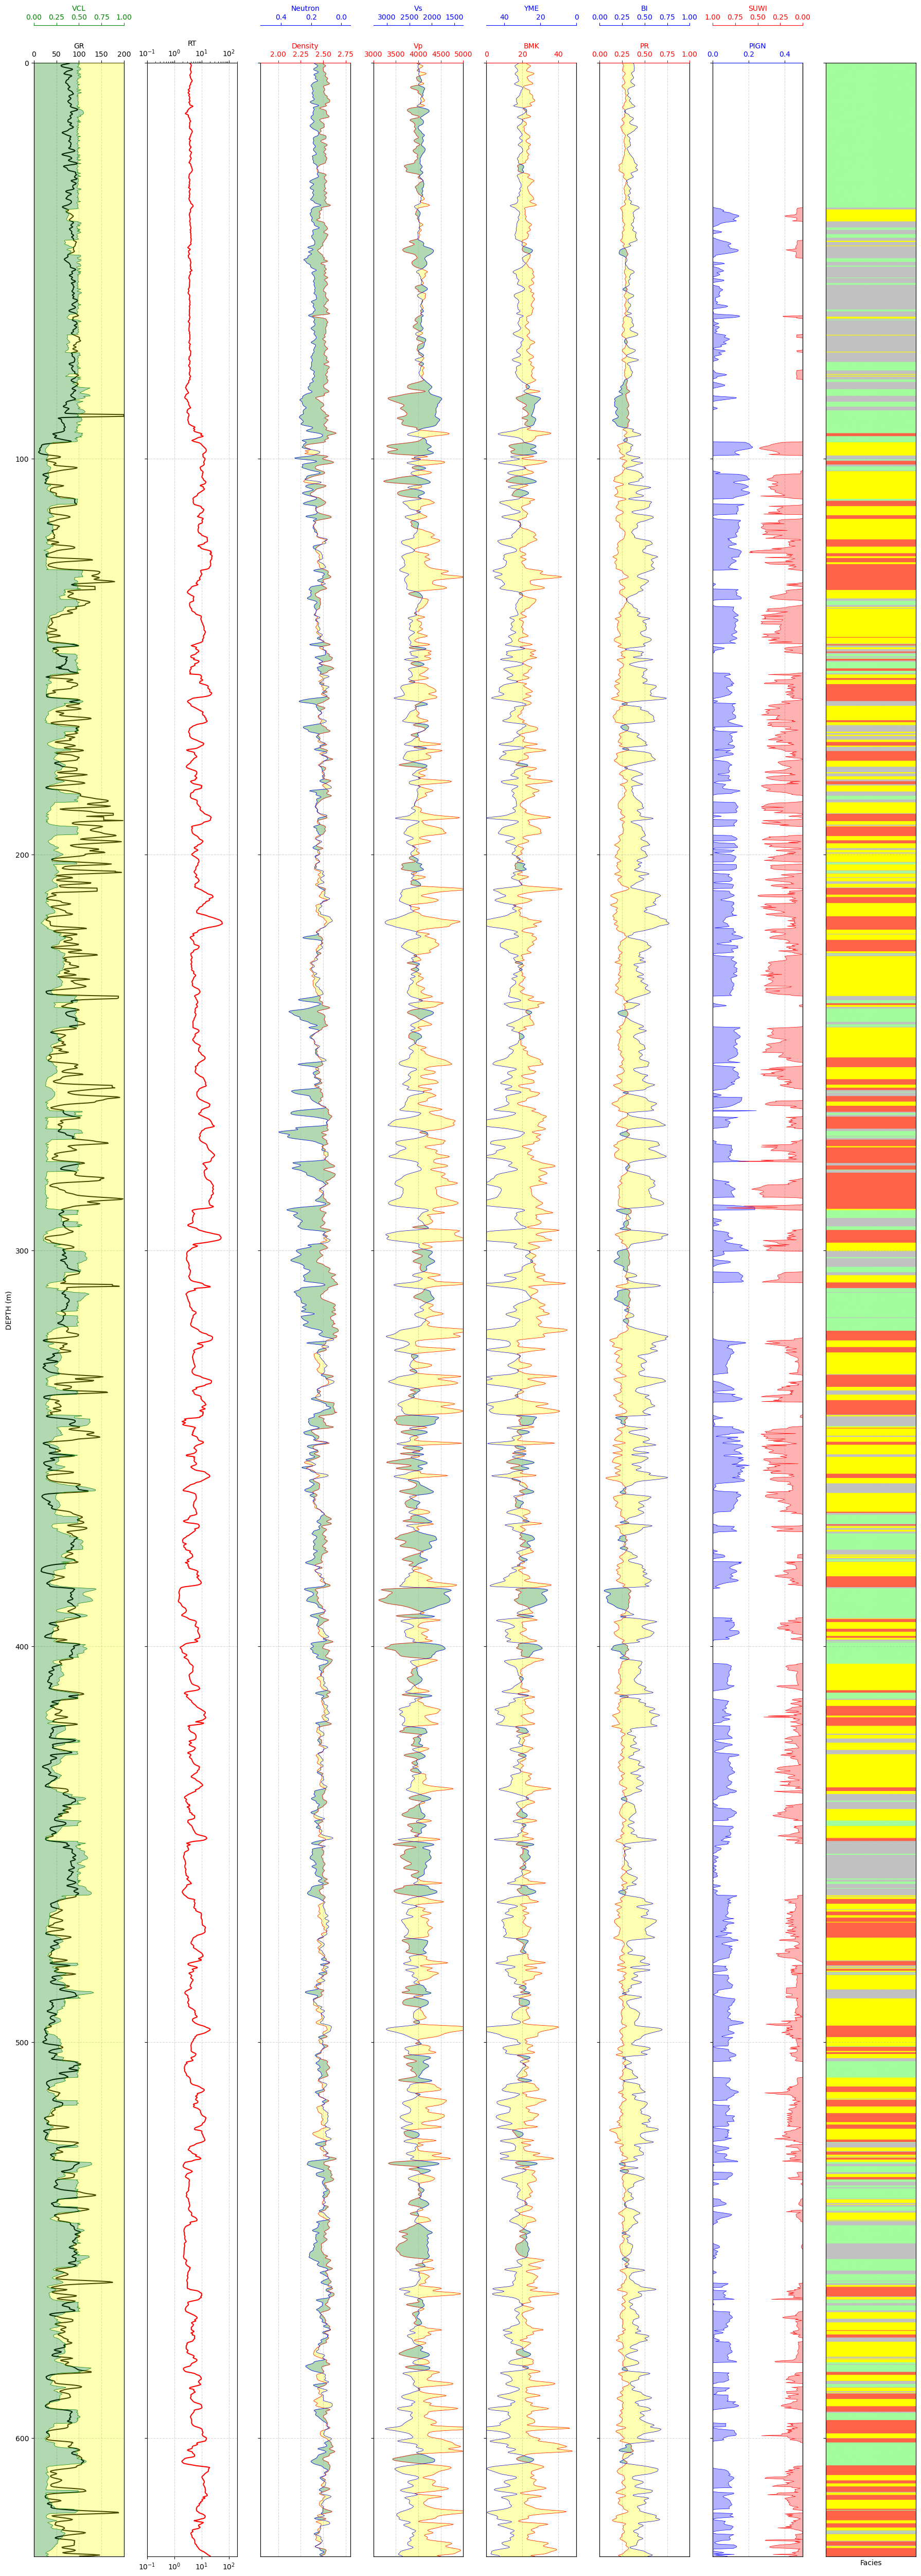

In [4]:
# =============================================================
# GENERATE WELL PLOT - PREDICTED FACIES
# =============================================================
def plot_elastic_multitrack(df_well_2, depth_col="DEPTH", gr_col="GR", facies_col="PREDICTED_FACIES"):
    # --- Data Prep ---
    facies_categories = ['Sandstone', 'Shale', 'Siltstone', 'Tight sandstone']
    lithology_numbers = {
        0: {'lith': 'Sandstone', 'hatch': '..', 'color': '#ffff00'},
        1: {'lith': 'Shale', 'hatch': '--', 'color': '#A2FD9D'},
        2: {'lith': 'Siltstone', 'hatch': 'xx', 'color': '#c1c1c1'},
        3: {'lith': 'Tight Sandstone', 'hatch': '///', 'color': '#ff6347'}
    }
    
    df_well_2[facies_col] = df_well_2[facies_col].str.lower()
    facies_mapping = {name.lower(): i for i, name in enumerate(facies_categories)}
    df_well_2['facies_code'] = df_well_2[facies_col].map(facies_mapping).fillna(-1).astype(int)

    cmap = mcolors.ListedColormap([lithology_numbers[i]['color'] for i in range(len(facies_categories))])
    
    depth = df_well_2[depth_col]
    fig, axes = plt.subplots(nrows=1, ncols=8, figsize=(18, 50), sharey=True)
    
    # --- Common Formatting ---
    for ax in axes:
        ax.set_ylim(depth.max(), depth.min())
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)

    # Helper function to enable top/bottom ticks on secondary (twin) axes
    def enable_twin_ticks(ax):
        ax.tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)
        # Ensure the twin axis spine is correctly positioned at the top
        ax.spines["top"].set_position(("axes", 1.0))

    # --- Tracks 2 & 4 (Cross-over fills) ---
    def add_crossover(ax, ax_twin, col1, col2, color_pos, color_neg):
        x1 = df_well_2[col1]
        x2 = df_well_2[col2]
        # Normalize to common plot space
        ax_lim = ax.get_xlim()
        twin_lim = ax_twin.get_xlim()
        
        # Scaling logic for crossover
        x2_norm = ((x2 - twin_lim[0]) / (twin_lim[1] - twin_lim[0])) * (ax_lim[1] - ax_lim[0]) + ax_lim[0]
        ax.fill_betweenx(depth, x1, x2_norm, where=x1 >= x2_norm, color=color_pos, interpolate=True, alpha=0.3)
        ax.fill_betweenx(depth, x1, x2_norm, where=x1 <= x2_norm, color=color_neg, interpolate=True, alpha=0.3)

    axes[0].set_ylabel(f"{depth_col} (m)")
    
    # Track 1: GR / VCL
    axes[0].plot(df_well_2[gr_col], depth, color="black")
    axes[0].set_xlim(0, 200)
    axes[0].set_xlabel("GR")
    axes[0].xaxis.label.set_color("black")
    axes[0].tick_params(axis='x', colors="black")
    axes[0].spines["top"].set_edgecolor("black")
    ax1 = axes[0].twiny()

    ax1.plot(df_well_2["VCL"], depth, color='green', lw=0.5)
    ax1.set_xlim(0, 1)
    ax1.set_xlabel('VCL')
    ax1.xaxis.label.set_color("green")
    ax1.spines["top"].set_position(("axes", 1.015))
    ax1.tick_params(axis='x', colors="green")
    ax1.spines["top"].set_edgecolor("green")

    ax1.fill_betweenx(df_well_2['DEPTH'], df_well_2['VCL'], 0, facecolor='green', alpha=0.3)
    ax1.fill_betweenx(df_well_2['DEPTH'], df_well_2['VCL'], 1, facecolor='yellow', alpha=0.3)

    for ax in [axes[0], ax1]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 2: RT
    axes[1].semilogx( df_well_2["RT"], depth, color="red")
    axes[1].set_xlim(0.1, 200)
    axes[1].set_xlabel("RT")
    axes[1].xaxis.set_ticks_position("top")
    axes[1].xaxis.set_label_position("top")
    axes[1].tick_params(axis='x', top=True, bottom=True, labeltop=True, labelbottom=True)

    # Track 3: RHOB/NPHI
    ax3 = axes[2].twiny()
    axes[2].plot(df_well_2["RHOB"], depth, color='red', lw=0.5)
    axes[2].set_xlim(1.8, 2.8)
    axes[2].set_xlabel('Density')
    axes[2].xaxis.label.set_color("red")
    axes[2].tick_params(axis='x', colors="red")
    axes[2].spines["top"].set_edgecolor("red")

    ax3.plot(df_well_2["NPHI"], depth, color='blue', lw=0.5)
    ax3.set_xlim(0.54, -0.06)
    ax3.set_xlabel('Neutron')
    ax3.xaxis.label.set_color("blue")
    ax3.spines["top"].set_position(("axes", 1.015))
    ax3.tick_params(axis='x', colors="blue")
    ax3.spines["top"].set_edgecolor("blue")

    add_crossover(axes[2], ax3, "RHOB", "NPHI", "green", "yellow")
    for ax in [axes[2], ax3]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 4: Vp/Vs
    ax4 = axes[3].twiny()
    axes[3].plot(df_well_2["Vp"], depth, color='red', lw=0.5)
    axes[3].set_xlim(3000, 5000)
    axes[3].set_xlabel('Vp')
    axes[3].xaxis.label.set_color("red")
    axes[3].tick_params(axis='x', colors="red")
    axes[3].spines["top"].set_edgecolor("red")

    ax4.plot(df_well_2["Vs"], depth, color='blue', lw=0.5)
    ax4.set_xlim(3300, 1300)
    ax4.set_xlabel('Vs')
    ax4.xaxis.label.set_color("blue")
    ax4.spines["top"].set_position(("axes", 1.015))
    ax4.tick_params(axis='x', colors="blue")
    ax4.spines["top"].set_edgecolor("blue")

    add_crossover(axes[3], ax4, "Vp", "Vs", "yellow", "green")
    for ax in [axes[3], ax4]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")

    # Track 5: Young's Modulus and BMK
    ax5 = axes[4].twiny()
    axes[4].plot(df_well_2["BMK"], depth, color='red', lw=0.5)
    axes[4].set_xlim(0, 50)
    axes[4].set_xlabel('BMK')
    axes[4].xaxis.label.set_color("red")
    axes[4].tick_params(axis='x', colors="red")
    axes[4].spines["top"].set_edgecolor("red")

    ax5.plot(df_well_2["YME"], depth, color='blue', lw=0.5)
    ax5.set_xlim(50, 0)
    ax5.set_xlabel('YME')
    ax5.xaxis.label.set_color("blue")
    ax5.spines["top"].set_position(("axes", 1.015))
    ax5.tick_params(axis='x', colors="blue")
    ax5.spines["top"].set_edgecolor("blue")
    add_crossover(axes[4], ax5, "BMK", "YME", "yellow", "green")
    
    for ax in [axes[4], ax5]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")

    # Track 6: PR and BI
    ax6 = axes[5].twiny()
    axes[5].plot(df_well_2["PR"], depth, color='red', lw=0.5)
    axes[5].set_xlim(0, 1)
    axes[5].set_xlabel('PR')
    axes[5].xaxis.label.set_color("red")
    axes[5].tick_params(axis='x', colors="red")
    axes[5].spines["top"].set_edgecolor("red")

    ax6.plot(df_well_2["BI"], depth, color='blue', lw=0.5)
    ax6.set_xlim(0, 1)
    ax6.set_xlabel('BI')
    ax6.xaxis.label.set_color("blue")
    ax6.spines["top"].set_position(("axes", 1.015))
    ax6.tick_params(axis='x', colors="blue")
    ax6.spines["top"].set_edgecolor("blue")
    add_crossover(axes[5], ax6, "PR", "BI", "green", "yellow")

    for ax in [axes[5], ax6]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
    
    # Track 7: PIGN Sw
    ax7 = axes[6].twiny()
    axes[6].plot(df_well_2["PIGN"], depth, color='blue', lw=0.5)
    axes[6].set_xlim(0, 0.5)
    axes[6].set_xlabel('PIGN')
    axes[6].xaxis.label.set_color("blue")
    axes[6].tick_params(axis='x', colors="blue")
    axes[6].spines["top"].set_edgecolor("blue")

    ax7.plot((df_well_2["SUWI"]), depth, color='red', lw=0.5)
    ax7.set_xlim(1, 0)
    ax7.set_xlabel('SUWI')
    ax7.xaxis.label.set_color("red")
    ax7.spines["top"].set_position(("axes", 1.015))
    ax7.tick_params(axis='x', colors="red")
    ax7.spines["top"].set_edgecolor("red")

    axes[6].fill_betweenx(df_well_2['DEPTH'], df_well_2['PIGN'], 0, facecolor='blue', alpha=0.3)
    ax7.fill_betweenx(df_well_2['DEPTH'], (df_well_2['SUWI']), 0, facecolor='red', alpha=0.3)

    for ax in [axes[6], ax7]:
        ax.xaxis.set_ticks_position("top")
        ax.xaxis.set_label_position("top")
   
    # Track 8: Facies with color and full-track hatching
    ax8 = axes[7] 
    
    # Calculate facies_codes if not already in scope
    facies_codes = df_well_2['facies_code'].values.reshape(-1, 1)
    extent = [0, 1, depth.max(), depth.min()]
    
    # Plot the color background
    ax8.imshow(facies_codes, aspect='auto', cmap=cmap, extent=extent, origin='upper')
    ax8.set_xlabel("Facies")
    ax8.set_xticks([])
    
    plt.tight_layout()
    plt.savefig(f"{WELL_2}_LogPlot.pdf")
    plt.savefig(f"fig-09-{WELL_2}_LogPlot.png")
    plt.show()
    
    # Call your function with your DataFrame
plot_elastic_multitrack(df_well_2)